In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(42)


n_rows = 500

categories = ['Electronics', 'Clothing', 'Home & Kitchen', 'Books', 'Beauty']
products = {
    'Electronics': ['Laptop', 'Headphones', 'Smartphone', 'Smartwatch'],
    'Clothing': ['T-Shirt', 'Jeans', 'Jacket', 'Sneakers'],
    'Home & Kitchen': ['Coffee Maker', 'Blender', 'Air Fryer'],
    'Books': ['Fiction Book', 'Tech Book', 'Self-Help Book'],
    'Beauty': ['Sunscreen', 'Perfume', 'Lipstick']
}

data = []
dates = pd.date_range(start='2023-01-01', end='2023-12-31', freq='D')

for i in range(n_rows):
    cat = np.random.choice(categories)
    prod = np.random.choice(products[cat])
    price = np.random.randint(10, 500)
    qty = np.random.randint(1, 5)
    date = np.random.choice(dates)
    
    data.append({
        'OrderID': 1000 + i,
        'Date': date,
        'Category': cat,
        'Product': prod,
        'UnitPrice': price,
        'Quantity': qty
    })

df_sales = pd.DataFrame(data)


df_sales['TotalSales'] = df_sales['UnitPrice'] * df_sales['Quantity']


total_revenue = df_sales['TotalSales'].sum()
total_orders = df_sales['OrderID'].nunique()
aov = total_revenue / total_orders

print("=== 📊 شاخص‌های کلیدی فروش (KPIs) ===")
print(f"مجموع کل درآمد: ${total_revenue:,.2f}")
print(f"تعداد کل سفارشات: {total_orders}")
print(f"متوسط ارزش هر سفارش (AOV): ${aov:.2f}\n")


category_summary = df_sales.groupby('Category')['TotalSales'].sum().reset_index()
category_summary = category_summary.sort_values(by='TotalSales', ascending=False)

print("=== 🛍️ فروش به تفکیک دسته‌بندی ===")
print(category_summary.to_string(index=False))

=== 📊 شاخص‌های کلیدی فروش (KPIs) ===
مجموع کل درآمد: $298,923.00
تعداد کل سفارشات: 500
متوسط ارزش هر سفارش (AOV): $597.85

=== 🛍️ فروش به تفکیک دسته‌بندی ===
      Category  TotalSales
      Clothing       66730
Home & Kitchen       64734
   Electronics       59508
         Books       55628
        Beauty       52323


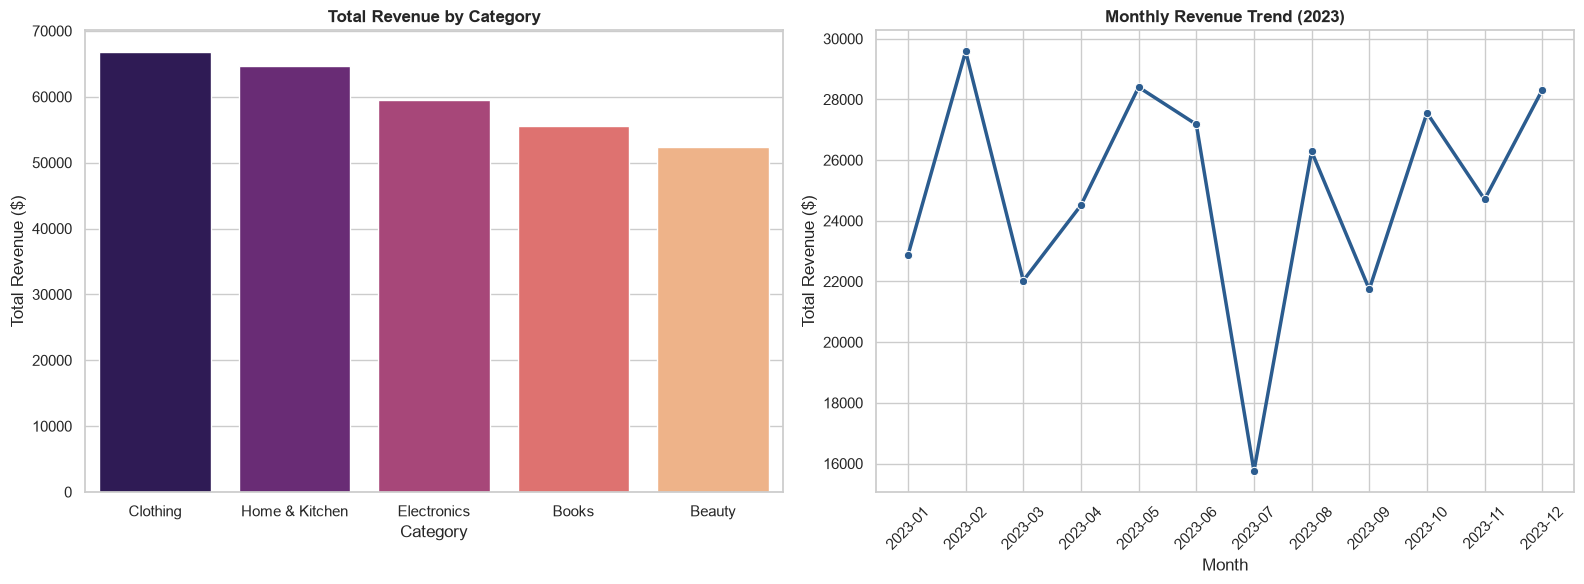

In [2]:
df_sales['Month'] = df_sales['Date'].dt.to_period('M')
monthly_sales = df_sales.groupby('Month')['TotalSales'].sum().reset_index()
monthly_sales['Month'] = monthly_sales['Month'].astype(str)


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.barplot(
    ax=axes[0], 
    data=category_summary, 
    x='Category', 
    y='TotalSales', 
    hue='Category', 
    palette='magma', 
    legend=False
)
axes[0].set_title('Total Revenue by Category', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Total Revenue ($)')


sns.lineplot(
    ax=axes[1], 
    data=monthly_sales, 
    x='Month', 
    y='TotalSales', 
    marker='o', 
    color='#2b5c8f', 
    linewidth=2.5
)
axes[1].set_title('Monthly Revenue Trend (2023)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Revenue ($)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()